# Telco Customer Churn: очистка данных и анализ (Часть 1)

**Автор:** Иванов Матвей Валерьевич, группа АД-24
**Блокнот 1 из 2.** Блокнот 2 (`Telco_Churn_2_Preprocessing.ipynb`) — предобработка и масштабирование.

**Датасет:** IBM *Telco Customer Churn* (Kaggle: `blastchar/telco-customer-churn`) — 7 043 клиента телеком-оператора, 21 столбец.
Целевая переменная — `Churn` (ушёл клиент или остался).

**Что делается в блокноте**

1. Очистка датасета: дубликаты, пропуски, логические ошибки — с пояснением каждого решения.
2. Часть 1 — анализ данных на 25 % датасета: графики, среднее и медиана, 5 гипотез, проверка гипотез на оставшихся 75 %, вывод.

Очищенный датасет сохраняется в `telco_clean.csv` и используется во втором блокноте.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

RANDOM_STATE = 42


def md(text):
    """Вывести строку как Markdown (удобно для комментариев с посчитанными числами)."""
    display(Markdown(text))

## 0. Загрузка и первичный осмотр

In [2]:
RAW_PATH = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_raw = pd.read_csv(RAW_PATH)
print(f'Строк: {df_raw.shape[0]}, столбцов: {df_raw.shape[1]}')
df_raw.head()

Строк: 7043, столбцов: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Описание столбцов**

| Группа | Столбцы |
|---|---|
| Идентификатор | `customerID` |
| Демография | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Срок и контракт | `tenure` (месяцев с клиентом), `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Телефония | `PhoneService`, `MultipleLines` |
| Интернет и допуслуги | `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Платежи | `MonthlyCharges` (текущий месячный платёж), `TotalCharges` (накопленная сумма платежей) |
| Цель | `Churn` |

Уже по `info()` видно странность: `TotalCharges` должен быть числом, но имеет строковый тип. Это признак «скрытых» пропусков — разберём ниже.

## 1. Очистка данных

### 1.1 Дубликаты

Проверяем три уровня: (а) полностью совпадающие строки, (б) повторы `customerID` (один клиент не может встречаться дважды),
(в) строки, совпадающие по всем признакам, кроме идентификатора.

In [4]:
feat_cols = [c for c in df_raw.columns if c != 'customerID']

n_full = df_raw.duplicated().sum()
n_id = df_raw['customerID'].duplicated().sum()
dup_extra = df_raw.duplicated(subset=feat_cols, keep='first')          # «лишние» копии
dup_all = df_raw[df_raw.duplicated(subset=feat_cols, keep=False)]      # все строки, участвующие в совпадениях

print(f'(а) Полностью одинаковых строк:            {n_full}')
print(f'(б) Повторяющихся customerID:              {n_id}')
print(f'(в) Строк-копий по признакам без ID:       {dup_extra.sum()}  '
      f'({dup_extra.mean():.2%} датасета); всего строк в таких группах: {len(dup_all)}')

groups = dup_all.groupby(feat_cols).size()
print(f'    Групп «похожих» клиентов: {len(groups)}, размер группы: от {groups.min()} до {groups.max()}')
print('\nХарактеристики клиентов в этих группах:')
print('  tenure:          ', dup_all['tenure'].value_counts().to_dict())
print('  Contract:        ', dup_all['Contract'].value_counts().to_dict())
print('  InternetService: ', dup_all['InternetService'].value_counts().to_dict())

dup_all.sort_values(feat_cols).head(8)

(а) Полностью одинаковых строк:            0
(б) Повторяющихся customerID:              0
(в) Строк-копий по признакам без ID:       22  (0.31% датасета); всего строк в таких группах: 42
    Групп «похожих» клиентов: 20, размер группы: от 2 до 3

Характеристики клиентов в этих группах:
  tenure:           {1: 42}
  Contract:         {'Month-to-month': 42}
  InternetService:  {'No': 26, 'Fiber optic': 12, 'DSL': 4}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
4495,4702-IOQDC,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
6267,0328-GRPMV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
5522,2619-WFQWU,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
5759,9985-MWVIX,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No


**Решение: ничего не удаляем.**

* Полных дубликатов и повторов `customerID` нет — значит, технических дублей записей (двойная выгрузка, ошибка объединения таблиц) в данных нет.
* Совпадения «без учёта ID» — это **разные клиенты** (у них разные `customerID`). Все они имеют `tenure = 1` и помесячный контракт:
  в датасете из 19 в основном категориальных признаков у новых клиентов с типовым тарифом одинаковый профиль встречается естественно
  (у `tenure = 1` ещё и `TotalCharges` равен `MonthlyCharges`, то есть почти все числовые «степени свободы» совпадают).
* Удаление таких строк исказило бы данные: мы выбросили бы реальных клиентов именно из самой «рискованной» категории (новички с помесячным контрактом).

### 1.2 Пропуски

`df.isna()` может показать «0 пропусков», хотя пропуски записаны пустыми строками или пробелами. Проверяем оба варианта.

In [5]:
df = df_raw.copy()

# убираем случайные пробелы по краям во всех текстовых столбцах
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].astype(str).str.strip()

print('Формальных NaN во всём датасете:', int(df_raw.isna().sum().sum()))

blank = {c: int(df[c].eq('').sum()) for c in text_cols}
print('Пустые строки по столбцам:', {k: v for k, v in blank.items() if v})

Формальных NaN во всём датасете: 0
Пустые строки по столбцам: {'TotalCharges': 11}


In [6]:
tc_num = pd.to_numeric(df['TotalCharges'], errors='coerce')
bad = df[tc_num.isna()]

display(bad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']])
print('Значения tenure у этих клиентов:', bad['tenure'].unique())
print('Churn у этих клиентов:          ', bad['Churn'].value_counts().to_dict())
print('Все ли клиенты с tenure == 0 попали в список?',
      set(df.index[df['tenure'] == 0]) == set(bad.index))

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


Значения tenure у этих клиентов: [0]
Churn у этих клиентов:           {'No': 11}
Все ли клиенты с tenure == 0 попали в список? True


**Что нашли.** Формальных пропусков нет, но в `TotalCharges` скрыто **11 пустых значений** (поэтому столбец и стал строковым).
Все 11 строк — клиенты с `tenure = 0`: они только что подключились и ещё не получили ни одного счёта.

**Решение: заполнить нулём** (`TotalCharges = 0`) и привести столбец к `float`.

* По смыслу это не «неизвестное» значение, а **известный ноль**: накопленная сумма платежей у клиента без единого расчётного периода равна 0.
* Заполнение медианой/средним (≈ 1 400–2 300 $) было бы логической ошибкой: мы приписали бы новичку платежи, которых не было.
* Удаление 11 строк тоже допустимо (0,16 %), но заполнение нулём сохраняет данные и ничего не искажает.

In [7]:
df['TotalCharges'] = tc_num
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0.0

assert df['TotalCharges'].notna().all()
print('Пропусков после обработки:', int(df.isna().sum().sum()))
print('Тип TotalCharges:', df['TotalCharges'].dtype)

Пропусков после обработки: 0
Тип TotalCharges: float64


### 1.3 Логические ошибки

Проверяем, что данные не противоречат здравому смыслу и друг другу: допустимые диапазоны, согласованность связанных столбцов, словари категорий.
Каждая проверка должна давать **0 нарушений**; если нарушения есть — их нужно разбирать.

In [8]:
svc = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
yes_no = {'Yes', 'No'}
domains = {
    'gender': {'Female', 'Male'},
    'Partner': yes_no, 'Dependents': yes_no, 'PhoneService': yes_no, 'PaperlessBilling': yes_no, 'Churn': yes_no,
    'MultipleLines': yes_no | {'No phone service'},
    'InternetService': {'DSL', 'Fiber optic', 'No'},
    'Contract': {'Month-to-month', 'One year', 'Two year'},
    'PaymentMethod': {'Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'},
    **{c: yes_no | {'No internet service'} for c in svc},
}
bad_domain = sum(int((~df[c].isin(v)).sum()) for c, v in domains.items())

checks = {
    'tenure вне диапазона 0–72 мес.':                                   ((df.tenure < 0) | (df.tenure > 72)).sum(),
    'MonthlyCharges <= 0':                                               (df.MonthlyCharges <= 0).sum(),
    'TotalCharges < 0':                                                  (df.TotalCharges < 0).sum(),
    'tenure = 0, но TotalCharges > 0':                                   ((df.tenure == 0) & (df.TotalCharges > 0)).sum(),
    'tenure >= 1, но TotalCharges < MonthlyCharges':                     ((df.tenure >= 1) & (df.TotalCharges < df.MonthlyCharges - 0.01)).sum(),
    'PhoneService и MultipleLines противоречат друг другу':              ((df.PhoneService == 'No') != (df.MultipleLines == 'No phone service')).sum(),
    'InternetService = No не согласован с допуслугами':                  ((df.InternetService == 'No') != (df[svc] == 'No internet service').all(axis=1)).sum(),
    'Интернет есть, но часть допуслуг помечена «No internet service»':   ((df.InternetService != 'No') & (df[svc] == 'No internet service').any(axis=1)).sum(),
    'SeniorCitizen не из {0, 1}':                                        (~df.SeniorCitizen.isin([0, 1])).sum(),
    'Значения категорий вне допустимого словаря':                        bad_domain,
    'customerID неверного формата (ожидается NNNN-XXXXX)':               (~df.customerID.str.match(r'^\d{4}-[A-Za-z]{5}$')).sum(),
    'Повторяющиеся customerID':                                          df.customerID.duplicated().sum(),
}
report = pd.DataFrame({'нарушений': pd.Series(checks).astype(int)})
report['статус'] = np.where(report['нарушений'] == 0, 'ОК', 'ПРОВЕРИТЬ')
report

,нарушений,статус
tenure вне диапазона 0–72 мес.,0,ОК
MonthlyCharges <= 0,0,ОК
TotalCharges < 0,0,ОК
"tenure = 0, но TotalCharges > 0",0,ОК
"tenure >= 1, но TotalCharges < MonthlyCharges",0,ОК
PhoneService и MultipleLines противоречат друг другу,0,ОК
InternetService = No не согласован с допуслугами,0,ОК
"Интернет есть, но часть допуслуг помечена «No internet service»",0,ОК
"SeniorCitizen не из {0, 1}",0,ОК
Значения категорий вне допустимого словаря,0,ОК


Все формальные проверки пройдены. Остаётся одна «мягкая» проверка правдоподобия: накопленная сумма `TotalCharges` должна быть
примерно равна `tenure × MonthlyCharges`. Точного равенства быть не обязано — тариф мог меняться, услуги подключались и отключались, —
но сильные расхождения стоит осмотреть.

In [9]:
m = df[df.tenure > 0].copy()
m['ratio'] = m['TotalCharges'] / (m['tenure'] * m['MonthlyCharges'])

print(m['ratio'].describe().round(3).to_string())
print(f"\nДоля клиентов, у кого ratio в пределах ±20 % от 1: {m['ratio'].between(0.8, 1.2).mean():.2%}")

print('\nСамые большие расхождения:')
display(m.loc[m['ratio'].sub(1).abs().sort_values(ascending=False).index[:5],
              ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ratio', 'Contract', 'InternetService']])

count    7032.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.573



Доля клиентов, у кого ratio в пределах ±20 % от 1: 99.16%

Самые большие расхождения:


,customerID,tenure,MonthlyCharges,TotalCharges,ratio,Contract,InternetService
5595,2308-STERM,2,19.40,61.05,1.573454,Month-to-month,No
869,0323-XWWTN,3,26.40,121.25,1.530934,Two year,No
5673,6260-XLACS,4,19.70,117.80,1.494924,One year,No
4689,2832-SCUCO,2,19.90,57.40,1.442211,Month-to-month,No
4634,9426-SXNHE,2,18.75,53.15,1.417333,Month-to-month,No


**Вывод по логике.** У подавляющего большинства клиентов (99 %) отношение лежит в пределах ±20 % от 1, а нижняя граница `TotalCharges ≥ MonthlyCharges` не нарушена нигде.
Самые большие отклонения — у клиентов с небольшим сроком (2–4 мес.) и низким платежом: у них даже небольшая разовая плата или смена тарифа заметно меняет отношение
(это наше предположение, в данных причина не указана). Такие значения возможны с точки зрения бизнеса и не противоречат другим столбцам, поэтому это **вариативность, а не ошибка ввода** — оставляем как есть.

Отдельно проверим выбросы в числовых столбцах правилом 1.5·IQR (информационно, удалять их не будем).

In [10]:
rows = []
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({'признак': c, 'нижняя граница': round(lo, 2), 'верхняя граница': round(hi, 2),
                 'выбросов': int(((df[c] < lo) | (df[c] > hi)).sum())})
pd.DataFrame(rows)

,признак,нижняя граница,верхняя граница,выбросов
0,tenure,-60.00,124.00,0
1,MonthlyCharges,-46.02,171.38,0
2,TotalCharges,-4683.52,8868.67,0


Выбросов по правилу 1.5·IQR нет, значения лежат в правдоподобных диапазонах (срок 0–72 мес., платёж 18–119 $).

### 1.4 Итог очистки

| Что проверяли | Результат | Действие |
|---|---|---|
| Полные дубликаты, повторы `customerID` | 0 | — |
| Совпадения по признакам без ID | 22 строки (tenure = 1, помесячный контракт) | оставлены: разные клиенты |
| Скрытые пропуски в `TotalCharges` | 11 (все с `tenure = 0`) | заполнены нулём, тип → `float` |
| Логические противоречия между столбцами | 0 | — |
| Допустимые диапазоны и словари категорий | 0 нарушений | — |
| Выбросы (1.5·IQR) | 0 | — |

Структурное замечание: значения `No internet service` и `No phone service` дублируют информацию из `InternetService` и `PhoneService`.
Это не ошибка, а избыточное кодирование; убирать его будем на этапе предобработки (блокнот 2), чтобы не менять исходный смысл данных здесь.

In [11]:
df_clean = df.copy()
df_clean.to_csv('telco_clean.csv', index=False)
print('Сохранено: telco_clean.csv', df_clean.shape)
print('Доля ушедших (Churn = Yes): {:.2%}'.format((df_clean['Churn'] == 'Yes').mean()))
df_clean.dtypes.to_frame('dtype').T

Сохранено: telco_clean.csv (7043, 21)
Доля ушедших (Churn = Yes): 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,str


## 2. Часть 1 — анализ данных

### 2.1 Выборка для исследования (25 %) и оставшаяся часть (75 %)

Берём **25 % датасета случайным образом** (`random_state = 42`). Выборка **стратифицирована по `Churn`**, чтобы доля ушедших клиентов в ней
совпадала с долей в целом датасете (26,5 %): иначе случайный перекос повлиял бы на графики и на сами гипотезы.

* `df_eda` — 25 %: на ней смотрим данные и **формулируем гипотезы**;
* `df_check` — оставшиеся 75 %: на ней **проверяем гипотезы**. Эти данные при формулировке гипотез не использовались — иначе проверка была бы нечестной
  (гипотезу, придуманную по тем же данным, почти всегда «подтверждает» то же самое наблюдение).

In [12]:
df_eda, df_check = train_test_split(df_clean, train_size=0.25, stratify=df_clean['Churn'], random_state=RANDOM_STATE)

summary = pd.DataFrame({
    'строк': [len(df_clean), len(df_eda), len(df_check)],
    'доля Churn=Yes': [(d['Churn'] == 'Yes').mean() for d in (df_clean, df_eda, df_check)],
}, index=['весь датасет', 'df_eda (25 %)', 'df_check (75 %)'])
summary['доля Churn=Yes'] = summary['доля Churn=Yes'].map('{:.2%}'.format)
summary

,строк,доля Churn=Yes
весь датасет,7043,26.54%
df_eda (25 %),1760,26.53%
df_check (75 %),5283,26.54%


### 2.2 Графики по признакам

**График 1. Распределения числовых признаков** (гистограмма, пунктиром — среднее и медиана).

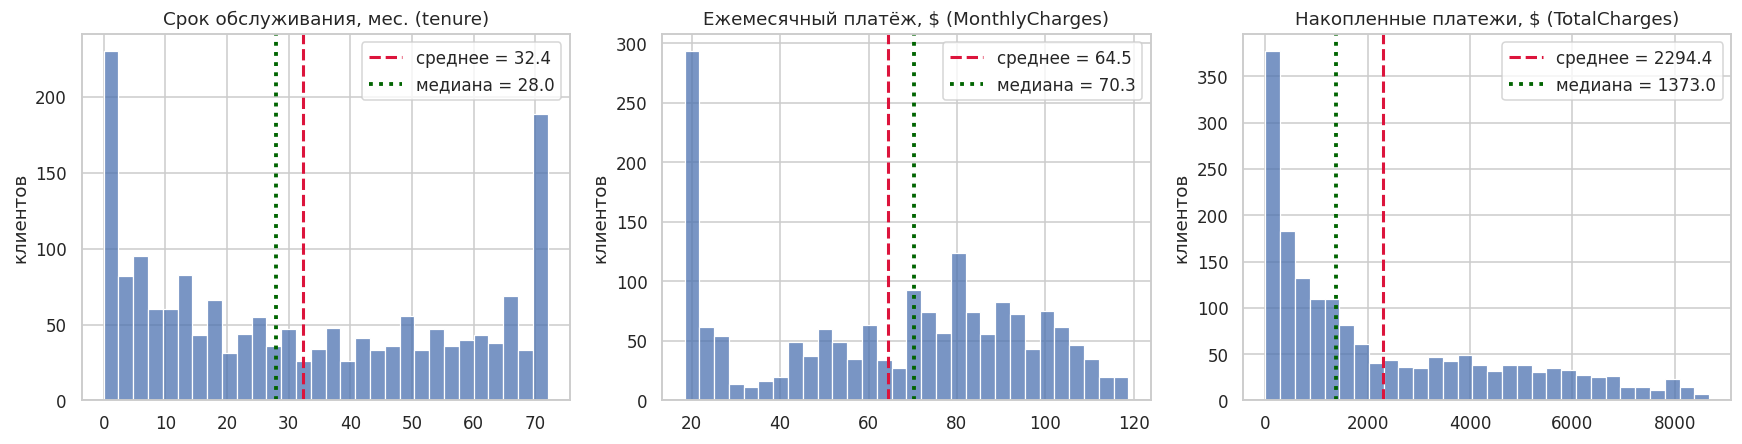

In [13]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
titles = {'tenure': 'Срок обслуживания, мес. (tenure)',
          'MonthlyCharges': 'Ежемесячный платёж, $ (MonthlyCharges)',
          'TotalCharges': 'Накопленные платежи, $ (TotalCharges)'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, num_cols):
    sns.histplot(df_eda[c], bins=30, color='#4C72B0', ax=ax)
    ax.axvline(df_eda[c].mean(), color='crimson', ls='--', lw=2, label=f'среднее = {df_eda[c].mean():.1f}')
    ax.axvline(df_eda[c].median(), color='darkgreen', ls=':', lw=2.5, label=f'медиана = {df_eda[c].median():.1f}')
    ax.set_title(titles[c]); ax.set_xlabel(''); ax.set_ylabel('клиентов')
    ax.legend()
plt.tight_layout(); plt.show()

**График 2. Те же признаки в разрезе `Churn`** (ящики с усами): отличаются ли ушедшие клиенты от оставшихся?

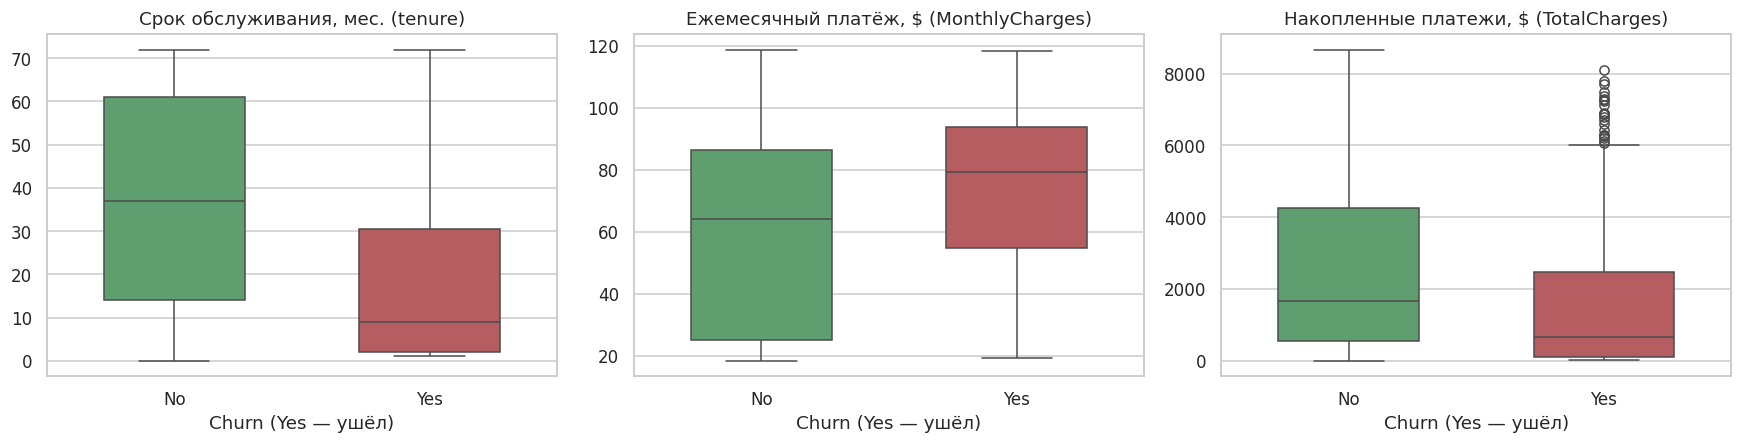

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
palette = {'No': '#55A868', 'Yes': '#C44E52'}
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df_eda, x='Churn', y=c, order=['No', 'Yes'], palette=palette, ax=ax, width=0.55)
    ax.set_title(titles[c]); ax.set_xlabel('Churn (Yes — ушёл)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**График 3. Доля ушедших клиентов по категориальным признакам** (пунктир — общая доля оттока в выборке).

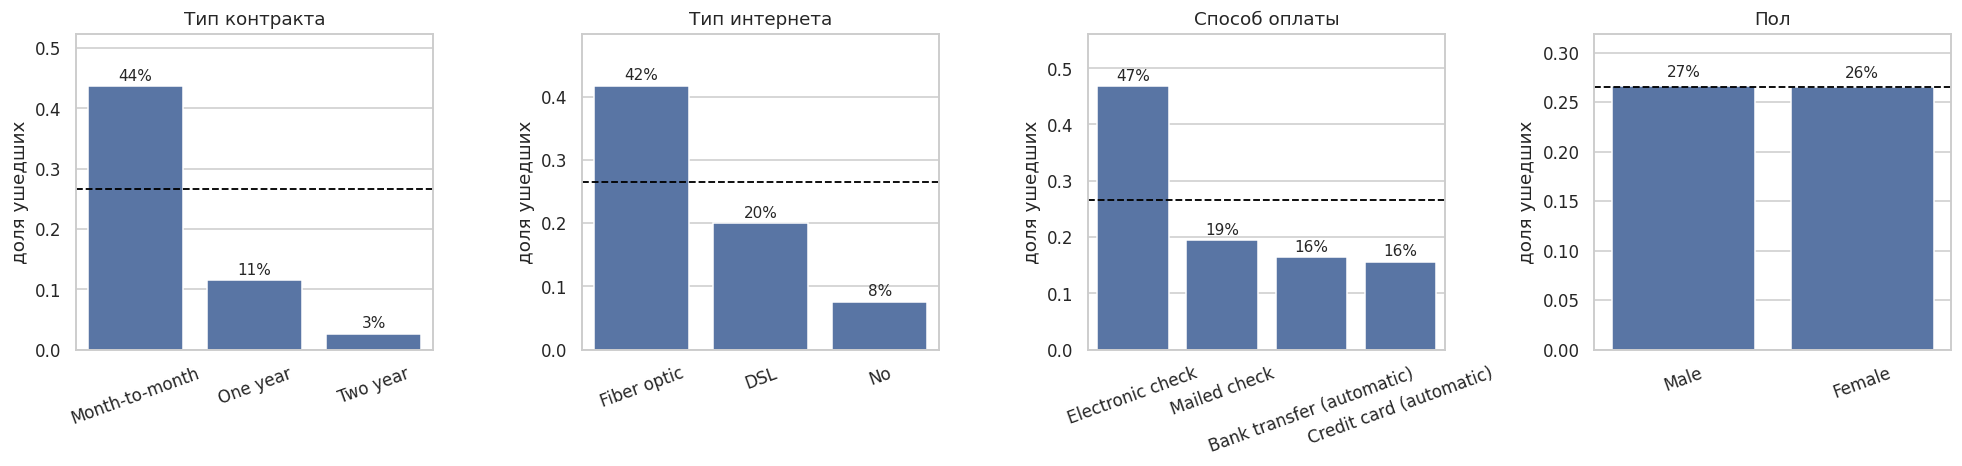

In [15]:
cat_cols = ['Contract', 'InternetService', 'PaymentMethod', 'gender']
cat_titles = {'Contract': 'Тип контракта', 'InternetService': 'Тип интернета',
              'PaymentMethod': 'Способ оплаты', 'gender': 'Пол'}
overall = (df_eda['Churn'] == 'Yes').mean()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, c in zip(axes, cat_cols):
    rate = (df_eda['Churn'] == 'Yes').groupby(df_eda[c]).mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, color='#4C72B0', ax=ax)
    ax.axhline(overall, color='black', ls='--', lw=1.2)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=10)
    ax.set_title(cat_titles[c]); ax.set_xlabel(''); ax.set_ylabel('доля ушедших')
    ax.set_ylim(0, max(rate.values) * 1.2)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

### 2.3 Среднее и медиана

Для числовых признаков считаем среднее и медиану — по всей выборке и отдельно для ушедших и оставшихся клиентов.

In [16]:
stat_all = df_eda[num_cols].agg(['mean', 'median']).T.round(2)
stat_all.columns = ['среднее', 'медиана']
stat_all['среднее − медиана'] = (stat_all['среднее'] - stat_all['медиана']).round(2)
stat_all['асимметрия (skew)'] = df_eda[num_cols].skew().round(2)
md('**Вся выборка (`df_eda`)**')
display(stat_all)

stat_grp = df_eda.groupby('Churn')[num_cols].agg(['mean', 'median']).round(2)
md('**В разрезе Churn**')
display(stat_grp)

**Вся выборка (`df_eda`)**

,среднее,медиана,среднее − медиана,асимметрия (skew)
tenure,32.36,28.00,4.36,0.25
MonthlyCharges,64.50,70.32,-5.82,-0.20
TotalCharges,2294.35,1373.02,921.33,0.95


**В разрезе Churn**

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.43   37.0          61.28  64.20      2561.72  1652.95
Yes    18.34    9.0          73.39  79.25      1554.07   654.85

In [17]:
t, mc, tc = stat_all.loc['tenure'], stat_all.loc['MonthlyCharges'], stat_all.loc['TotalCharges']
g = df_eda.groupby('Churn')
md(f"""
**Как читать:**

* **`TotalCharges`**: среднее ({tc['среднее']:.0f} $) заметно больше медианы ({tc['медиана']:.0f} $), асимметрия {tc['асимметрия (skew)']:.2f} — распределение скошено вправо
  (много новых клиентов с малой накопленной суммой и «хвост» долгих клиентов). Для описания «типичного» клиента медиана надёжнее.
* **`MonthlyCharges`**: медиана ({mc['медиана']:.1f} $) больше среднего ({mc['среднее']:.1f} $) — лёгкая скошенность влево и **двугорбость**:
  отдельный пик около 20 $ — это клиенты без интернета (только телефония), основная масса — 60–110 $.
* **`tenure`**: среднее ({t['среднее']:.1f}) и медиана ({t['медиана']:.0f}) близки, распределение примерно симметрично, но с двумя «пиками»
  (самые новые и самые давние клиенты).
* **Ушедшие vs оставшиеся:** медианный срок обслуживания ушедших — **{g['tenure'].median()['Yes']:.0f} мес.** против **{g['tenure'].median()['No']:.0f} мес.** у оставшихся;
  медианный месячный платёж — **{g['MonthlyCharges'].median()['Yes']:.1f} $** против **{g['MonthlyCharges'].median()['No']:.1f} $**.
""")


**Как читать:**

* **`TotalCharges`**: среднее (2294 $) заметно больше медианы (1373 $), асимметрия 0.95 — распределение скошено вправо
  (много новых клиентов с малой накопленной суммой и «хвост» долгих клиентов). Для описания «типичного» клиента медиана надёжнее.
* **`MonthlyCharges`**: медиана (70.3 $) больше среднего (64.5 $) — лёгкая скошенность влево и **двугорбость**:
  отдельный пик около 20 $ — это клиенты без интернета (только телефония), основная масса — 60–110 $.
* **`tenure`**: среднее (32.4) и медиана (28) близки, распределение примерно симметрично, но с двумя «пиками»
  (самые новые и самые давние клиенты).
* **Ушедшие vs оставшиеся:** медианный срок обслуживания ушедших — **9 мес.** против **37 мес.** у оставшихся;
  медианный месячный платёж — **79.2 $** против **64.2 $**.


### 2.4 Гипотезы

Гипотезы формулируются **по выборке `df_eda`** (25 %) и проверяются на **независимой части `df_check`** (75 %).

Так как проверяется несколько гипотез сразу, повышается риск случайно «найти» эффект. Поэтому используем **поправку Бонферрони**:
уровень значимости для каждой гипотезы $\alpha = 0{,}05 / 5 = 0{,}01$.

#### Ход мыслей: как появились гипотезы

**H1 — срок обслуживания.** На графике 2 ящик `tenure` для ушедших клиентов расположен намного ниже, чем для оставшихся, а медианы различаются в разы
(см. таблицу выше). Логика: новый клиент ещё не «привык» к оператору и не накопил привязанности/выгоды от долгого обслуживания, поэтому уходит легче.
*Гипотеза:* ушедшие клиенты имели меньший срок обслуживания, чем оставшиеся.

**H2 — тип контракта.** На графике 3 доля оттока для `Month-to-month` в несколько раз выше, чем для контрактов на год и два. Логика: помесячный контракт
не создаёт обязательств и штрафов за уход — расторгнуть его проще всего.
*Гипотеза:* среди клиентов с помесячным контрактом доля ушедших выше, чем среди клиентов с годовым и двухлетним контрактами.

**H3 — ежемесячный платёж.** По графику 2 и таблице медианных платежей ушедшие клиенты платили в среднем больше. Логика: чем выше счёт, тем острее клиент
реагирует на цену и тем охотнее рассматривает конкурентов.
*Гипотеза:* ежемесячный платёж ушедших клиентов выше, чем у оставшихся.

**H4 — оптоволоконный интернет.** H3 заставляет спросить, *почему* платёж выше. В выборке у клиентов с `Fiber optic` ежемесячный платёж заметно выше, чем у `DSL`,
и именно у них (график 3) высокая доля оттока. Возможно, «цена» — лишь маркер типа услуги. Логика: оптоволокно — дорогой и более конкурентный сегмент
(есть альтернативы), либо клиенты недовольны соотношением цены и качества.
*Гипотеза:* доля ушедших среди клиентов с `Fiber optic` выше, чем среди клиентов с `DSL`.

**H5 — пол (контрольная гипотеза «нет эффекта»).** На графике 3 столбцы для мужчин и женщин практически одинаковы. Логика: пол не должен влиять
на решение остаться или уйти, если оператор не дискриминирует клиентов. Нужна и гипотеза, которая *не* подтверждается: она показывает, что наш метод не «находит» различия везде подряд.
*Гипотеза:* доли ушедших среди мужчин и женщин различаются.

| № | Что проверяем | Нулевая гипотеза H₀ | Альтернатива H₁ | Критерий и почему он |
|---|---|---|---|---|
| H1 | `tenure` ушедших vs оставшихся | распределения одинаковы | у ушедших значения меньше | **Манна–Уитни** (односторонний): `tenure` не нормален и дискретен, критерий работает с рангами |
| H2 | отток: помесячный vs остальные контракты | доли равны | доля у помесячных выше | **z-тест для двух долей** (односторонний) + общий **χ²** по трём типам контракта |
| H3 | `MonthlyCharges` ушедших vs оставшихся | распределения одинаковы | у ушедших значения больше | **Манна–Уитни** (односторонний): платёж двугорбый, не нормален |
| H4 | отток: Fiber optic vs DSL | доли равны | доля у Fiber выше | **z-тест для двух долей** (односторонний) |
| H5 | отток: мужчины vs женщины | доли равны | доли различаются | **χ² независимости** (двусторонний) |

Для каждой проверки считаем ещё и **размер эффекта** (значимость при большой выборке бывает у любых мелочей): ранговую бисериальную корреляцию $r$
для Манна–Уитни и $V$ Крамера для χ².

In [18]:
ALPHA = 0.05
N_HYP = 5
ALPHA_ADJ = ALPHA / N_HYP          # поправка Бонферрони
results = []


def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))


def two_prop_ztest(x1, n1, x2, n2, alternative='greater'):
    """z-тест для разности двух долей (объединённая оценка дисперсии под H0) + 95 % ДИ разности."""
    p1, p2 = x1 / n1, x2 / n2
    p = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    pval = {'greater': stats.norm.sf(z), 'less': stats.norm.cdf(z), 'two-sided': 2 * stats.norm.sf(abs(z))}[alternative]
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1, p2, z, pval, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se)


def mann_whitney(a, b, alternative):
    """a — группа «ушли», b — группа «остались». r = 2U/(n1*n2) − 1 (ранговая бисериальная корреляция)."""
    U, p = stats.mannwhitneyu(a, b, alternative=alternative)
    return U, p, 2 * U / (len(a) * len(b)) - 1


def add_result(name, test, stat, p, eff_name, eff, decision_text, direction_ok=True):
    significant = (p < ALPHA_ADJ)
    results.append({'гипотеза': name, 'критерий': test, 'статистика': round(float(stat), 3),
                    'p-value': p, 'эффект': f'{eff_name} = {eff:.3f}',
                    'решение (α = %.2f)' % ALPHA_ADJ: 'H₀ отвергается' if significant else 'H₀ не отвергается'})


churn_yes = df_check[df_check['Churn'] == 'Yes']
churn_no = df_check[df_check['Churn'] == 'No']
print(f'Проверочная часть: {len(df_check)} клиентов (ушли: {len(churn_yes)}, остались: {len(churn_no)})')

Проверочная часть: 5283 клиентов (ушли: 1402, остались: 3881)


#### H1. Срок обслуживания ушедших меньше

In [19]:
U, p, r = mann_whitney(churn_yes['tenure'], churn_no['tenure'], alternative='less')
add_result('H1: tenure ушедших < оставшихся', 'Манна–Уитни (less)', U, p, 'r', r, '')

md(f"""
* Медиана `tenure`: ушедшие — **{churn_yes['tenure'].median():.0f}** мес., оставшиеся — **{churn_no['tenure'].median():.0f}** мес.
* Манна–Уитни: U = {U:,.0f}, **p = {p:.2e}**, ранговая бисериальная корреляция r = {r:.3f} (знак минус — у ушедших значения ниже).
* Вывод: при α = {ALPHA_ADJ} H₀ **{'отвергается' if p < ALPHA_ADJ else 'не отвергается'}**.
""")


* Медиана `tenure`: ушедшие — **10** мес., оставшиеся — **38** мес.
* Манна–Уитни: U = 1,405,507, **p = 1.92e-159**, ранговая бисериальная корреляция r = -0.483 (знак минус — у ушедших значения ниже).
* Вывод: при α = 0.01 H₀ **отвергается**.


#### H2. Помесячные контракты чаще заканчиваются уходом

In [20]:
ct = pd.crosstab(df_check['Contract'], df_check['Churn'])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
v = cramers_v(ct)
rates = (df_check['Churn'] == 'Yes').groupby(df_check['Contract']).mean()
display(pd.concat([ct, rates.rename('доля ушедших').map('{:.1%}'.format)], axis=1))

mtm = df_check['Contract'] == 'Month-to-month'
x1, n1 = int((df_check.loc[mtm, 'Churn'] == 'Yes').sum()), int(mtm.sum())
x2, n2 = int((df_check.loc[~mtm, 'Churn'] == 'Yes').sum()), int((~mtm).sum())
p1, p2, z, p_z, ci = two_prop_ztest(x1, n1, x2, n2, alternative='greater')
add_result('H2: отток при помесячном контракте выше', 'z-тест двух долей (greater)', z, p_z, 'V Крамера (χ², 3 контракта)', v, '')

md(f"""
* Доля ушедших: помесячный контракт — **{p1:.1%}**, годовой и двухлетний вместе — **{p2:.1%}**; разность {p1 - p2:.1%}, 95 % ДИ [{ci[0]:.1%}; {ci[1]:.1%}].
* z-тест: z = {z:.1f}, **p = {p_z:.2e}**. Общий χ² по трём типам контракта: χ² = {chi2:.1f}, p = {p_chi:.2e}, V Крамера = {v:.3f}.
* Вывод: при α = {ALPHA_ADJ} H₀ **{'отвергается' if p_z < ALPHA_ADJ else 'не отвергается'}**.
""")

,No,Yes,доля ушедших
Contract,,,
Month-to-month,1685,1241,42.4%
One year,990,125,11.2%
Two year,1206,36,2.9%



* Доля ушедших: помесячный контракт — **42.4%**, годовой и двухлетний вместе — **6.8%**; разность 35.6%, 95 % ДИ [33.5%; 37.6%].
* z-тест: z = 29.1, **p = 1.10e-186**. Общий χ² по трём типам контракта: χ² = 868.6, p = 2.42e-189, V Крамера = 0.405.
* Вывод: при α = 0.01 H₀ **отвергается**.


#### H3. Ежемесячный платёж ушедших выше

In [21]:
U, p, r = mann_whitney(churn_yes['MonthlyCharges'], churn_no['MonthlyCharges'], alternative='greater')
add_result('H3: MonthlyCharges ушедших > оставшихся', 'Манна–Уитни (greater)', U, p, 'r', r, '')

md(f"""
* Медиана `MonthlyCharges`: ушедшие — **{churn_yes['MonthlyCharges'].median():.1f} $**, оставшиеся — **{churn_no['MonthlyCharges'].median():.1f} $**.
* Манна–Уитни: U = {U:,.0f}, **p = {p:.2e}**, r = {r:.3f}.
* Вывод: при α = {ALPHA_ADJ} H₀ **{'отвергается' if p < ALPHA_ADJ else 'не отвергается'}**.
""")


* Медиана `MonthlyCharges`: ушедшие — **79.7 $**, оставшиеся — **64.5 $**.
* Манна–Уитни: U = 3,395,306, **p = 1.58e-43**, r = 0.248.
* Вывод: при α = 0.01 H₀ **отвергается**.


In [22]:
# Дополнительная проверка (на конфаундер): сохраняется ли разница платежей внутри одного типа интернета?
rows = []
for grp in ['DSL', 'Fiber optic', 'No']:
    sub = df_check[df_check['InternetService'] == grp]
    a, b = sub.loc[sub['Churn'] == 'Yes', 'MonthlyCharges'], sub.loc[sub['Churn'] == 'No', 'MonthlyCharges']
    U_, p_, r_ = mann_whitney(a, b, alternative='two-sided')
    rows.append({'InternetService': grp, 'клиентов': len(sub),
                 'медиана платежа (ушли), $': a.median(), 'медиана платежа (остались), $': b.median(),
                 'r': round(r_, 3), 'p-value (двусторонний)': p_})
conf = pd.DataFrame(rows).round(3)
conf['p-value (двусторонний)'] = conf['p-value (двусторонний)'].map(lambda x: '< 1e-10' if x < 1e-10 else (f'{x:.1e}' if x < 0.001 else f'{x:.3f}'))
conf

,InternetService,клиентов,"медиана платежа (ушли), $","медиана платежа (остались), $",r,p-value (двусторонний)
0,DSL,1804,49.625,59.55,-0.383,< 1e-10
1,Fiber optic,2339,88.325,94.80,-0.263,< 1e-10
2,No,1140,20.075,20.15,-0.127,0.052


**Важное наблюдение (парадокс Симпсона).** В целом ушедшие клиенты платят больше, но **внутри каждого типа интернета картина обратная**:
у `DSL` и `Fiber optic` медианный платёж ушедших *ниже*, чем у оставшихся (r < 0, различие значимо); у клиентов без интернета разница незначима.
Значит, результат H3 объясняется **составом клиентов**, а не самой ценой: среди ушедших гораздо больше пользователей дорогого оптоволокна (см. H4), и это «тянет» общий платёж вверх.
Высокий счёт сам по себе причиной ухода считать нельзя. Почему внутри одного типа интернета уходят те, кто платит меньше (возможно, у них меньше платных допуслуг), — это уже новая гипотеза, мы её не проверяли.

#### H4. Среди клиентов с оптоволокном отток выше, чем среди клиентов с DSL

In [23]:
sub = df_check[df_check['InternetService'].isin(['Fiber optic', 'DSL'])]
fib = sub['InternetService'] == 'Fiber optic'
x1, n1 = int((sub.loc[fib, 'Churn'] == 'Yes').sum()), int(fib.sum())
x2, n2 = int((sub.loc[~fib, 'Churn'] == 'Yes').sum()), int((~fib).sum())
p1, p2, z, p_z, ci = two_prop_ztest(x1, n1, x2, n2, alternative='greater')
v = cramers_v(pd.crosstab(sub['InternetService'], sub['Churn']))
add_result('H4: отток Fiber optic > DSL', 'z-тест двух долей (greater)', z, p_z, 'V Крамера', v, '')

md(f"""
* Доля ушедших: Fiber optic — **{p1:.1%}** (n = {n1}), DSL — **{p2:.1%}** (n = {n2}); разность {p1 - p2:.1%}, 95 % ДИ [{ci[0]:.1%}; {ci[1]:.1%}].
* z-тест: z = {z:.1f}, **p = {p_z:.2e}**, V Крамера = {v:.3f}.
* Вывод: при α = {ALPHA_ADJ} H₀ **{'отвергается' if p_z < ALPHA_ADJ else 'не отвергается'}**.
""")


* Доля ушедших: Fiber optic — **42.0%** (n = 2339), DSL — **18.6%** (n = 1804); разность 23.4%, 95 % ДИ [20.7%; 26.0%].
* z-тест: z = 16.0, **p = 5.85e-58**, V Крамера = 0.249.
* Вывод: при α = 0.01 H₀ **отвергается**.


#### H5. Контрольная гипотеза: пол и отток

In [24]:
ct = pd.crosstab(df_check['gender'], df_check['Churn'])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
v = cramers_v(ct)
rates = (df_check['Churn'] == 'Yes').groupby(df_check['gender']).mean()
add_result('H5: доля оттока различается по полу', 'χ² независимости (two-sided)', chi2, p_chi, 'V Крамера', v, '')

md(f"""
* Доля ушедших: женщины — **{rates['Female']:.1%}**, мужчины — **{rates['Male']:.1%}**.
* χ² = {chi2:.2f}, **p = {p_chi:.3f}**, V Крамера = {v:.3f}.
* Вывод: при α = {ALPHA_ADJ} H₀ **{'отвергается' if p_chi < ALPHA_ADJ else 'не отвергается'}**.
""")


* Доля ушедших: женщины — **27.1%**, мужчины — **26.0%**.
* χ² = 0.69, **p = 0.408**, V Крамера = 0.012.
* Вывод: при α = 0.01 H₀ **не отвергается**.


#### Сводная таблица результатов

**Графическая проверка на проверочной части (75 %).**

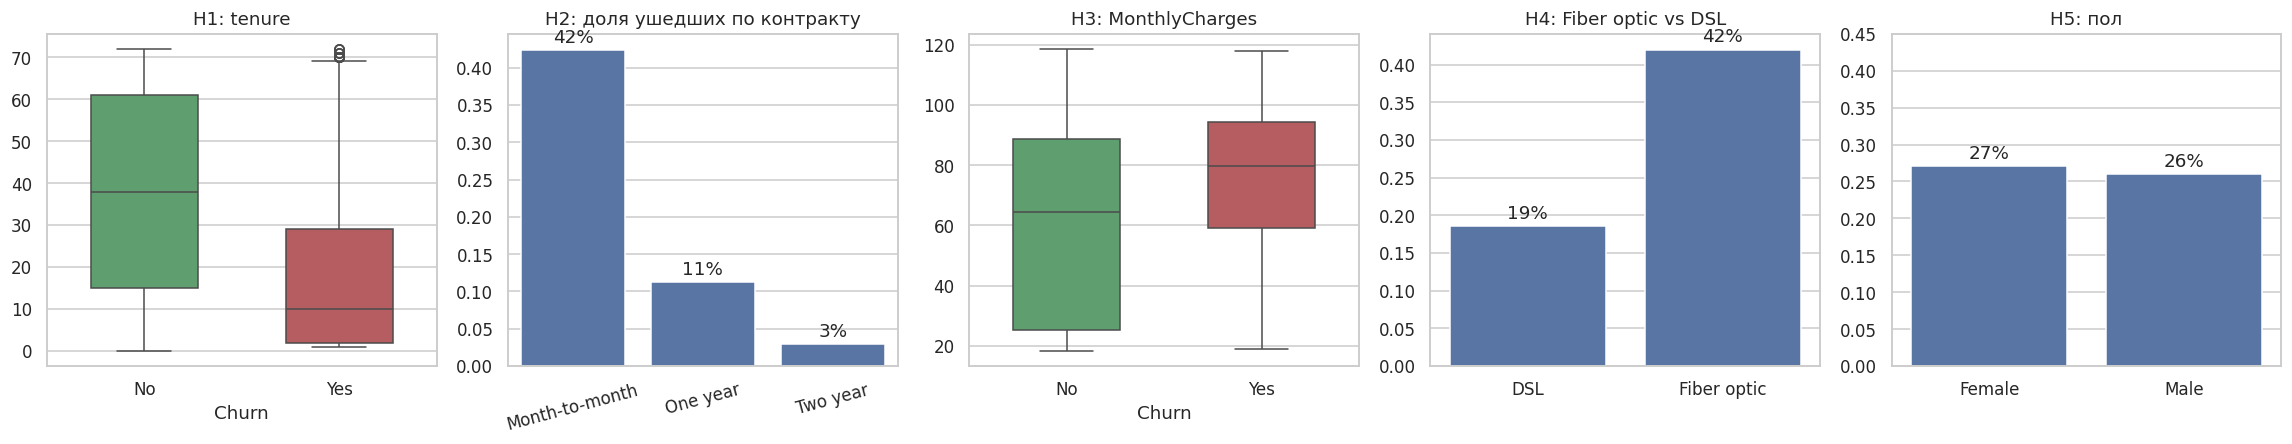

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.2))

sns.boxplot(data=df_check, x='Churn', y='tenure', order=['No', 'Yes'], palette=palette, ax=axes[0], width=0.55)
axes[0].set_title('H1: tenure'); axes[0].set_xlabel('Churn'); axes[0].set_ylabel('')

r_ = (df_check['Churn'] == 'Yes').groupby(df_check['Contract']).mean().reindex(['Month-to-month', 'One year', 'Two year'])
sns.barplot(x=r_.index, y=r_.values, color='#4C72B0', ax=axes[1])
axes[1].set_title('H2: доля ушедших по контракту'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=15)
for i, val in enumerate(r_.values):
    axes[1].text(i, val + 0.01, f'{val:.0%}', ha='center')

sns.boxplot(data=df_check, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], palette=palette, ax=axes[2], width=0.55)
axes[2].set_title('H3: MonthlyCharges'); axes[2].set_xlabel('Churn'); axes[2].set_ylabel('')

r_ = (sub['Churn'] == 'Yes').groupby(sub['InternetService']).mean()
sns.barplot(x=r_.index, y=r_.values, color='#4C72B0', ax=axes[3])
axes[3].set_title('H4: Fiber optic vs DSL'); axes[3].set_xlabel(''); axes[3].set_ylabel('')
for i, val in enumerate(r_.values):
    axes[3].text(i, val + 0.01, f'{val:.0%}', ha='center')

r_ = (df_check['Churn'] == 'Yes').groupby(df_check['gender']).mean()
sns.barplot(x=r_.index, y=r_.values, color='#4C72B0', ax=axes[4])
axes[4].set_title('H5: пол'); axes[4].set_xlabel(''); axes[4].set_ylabel('')
axes[4].set_ylim(0, 0.45)
for i, val in enumerate(r_.values):
    axes[4].text(i, val + 0.01, f'{val:.0%}', ha='center')

plt.tight_layout(); plt.show()

In [26]:
res = pd.DataFrame(results)
res['p-value'] = res['p-value'].map(lambda x: f'{x:.2e}' if x < 0.001 else f'{x:.3f}')
res

,гипотеза,критерий,статистика,p-value,эффект,решение (α = 0.01)
0,H1: tenure ушедших < оставшихся,Манна–Уитни (less),1405507.000,1.92e-159,r = -0.483,H₀ отвергается
1,H2: отток при помесячном контракте выше,z-тест двух долей (greater),29.117,1.10e-186,"V Крамера (χ², 3 контракта) = 0.405",H₀ отвергается
2,H3: MonthlyCharges ушедших > оставшихся,Манна–Уитни (greater),3395305.500,1.58e-43,r = 0.248,H₀ отвергается
3,H4: отток Fiber optic > DSL,z-тест двух долей (greater),16.005,5.85e-58,V Крамера = 0.249,H₀ отвергается
4,H5: доля оттока различается по полу,χ² независимости (two-sided),0.686,0.408,V Крамера = 0.012,H₀ не отвергается


### 2.5 Вывод

**Очистка данных.** Датасет оказался почти чистым: полных дубликатов и повторов `customerID` нет, логических противоречий между столбцами нет, выбросов по правилу 1.5·IQR нет.
Единственный реальный дефект — **11 скрытых пропусков в `TotalCharges`** (пустые строки у клиентов с `tenure = 0`); они заполнены нулём, потому что у таких клиентов ещё не было ни одного платежа.
22 строки, совпадающие по всем признакам кроме ID, сохранены: это разные клиенты с типовым профилем (`tenure = 1`, помесячный контракт).

**Описательная статистика (25 % выборки).** Отток составляет 26,5 %. Ушедшие клиенты — «новые и дорогие»: медианный срок обслуживания **9 мес. против 37**, медианный платёж **79 $ против 64 $**.
`TotalCharges` скошен вправо (среднее 2 294 $ заметно выше медианы 1 373 $), поэтому для типичного значения надёжнее медиана; `MonthlyCharges` двугорбый (пик около 20 $ — клиенты без интернета).

**Проверка гипотез на независимых 75 % данных** (α = 0,01 с поправкой Бонферрони на 5 гипотез):

| Гипотеза | Итог | Что показали данные |
|---|---|---|
| H1: ушедшие имели меньший `tenure` | подтверждена | медианы 10 и 38 мес., r = −0,48 (эффект умеренный-сильный) |
| H2: у помесячных контрактов отток выше | подтверждена | 42,4 % против 6,8 % у годовых и двухлетних, V = 0,41 — самая сильная связь из проверенных |
| H3: ушедшие платят больше | подтверждена **формально** | медианы 79,7 $ и 64,5 $, r = 0,25 (эффект слабый); но внутри типа интернета связь обратная — это эффект состава клиентов (парадокс Симпсона) |
| H4: у Fiber optic отток выше, чем у DSL | подтверждена | 42,0 % против 18,6 %, V = 0,25 |
| H5: отток различается по полу | **не подтверждена** | 27,1 % и 26,0 %, p = 0,41, V = 0,01: пол на отток не влияет |

Все эффекты, замеченные на 25 % выборке, **воспроизвелись на независимой части данных** — значит, они не случайный артефакт выборки.

**Итоговый портрет клиента из группы риска:** недавно подключившийся (первый год), с помесячным контрактом и оптоволоконным интернетом.
Практические выводы для оператора: стимулировать переход на годовые контракты (скидки, бонусы), уделять внимание клиентам в первые месяцы обслуживания, разобраться с качеством и ценой оптоволокна.

**Ограничения.**
* Это связи, а не причины: наблюдательные данные не доказывают, что смена контракта *снизит* отток.
* Признаки связаны между собой (`tenure`, `Contract`, `TotalCharges ≈ tenure × MonthlyCharges`), поэтому влияние каждого по отдельности нельзя читать независимо; пример — H3.
* Данные — один срез без дат, динамику оттока по времени оценить нельзя; классы несбалансированы (26,5 % ушедших), что важно учитывать при моделировании.
* Мы проверили 5 заранее выбранных гипотез; остальные признаки (способ оплаты, техподдержка, семья и др.) остались за рамками работы.

В блокноте 2 очищенные данные (`telco_clean.csv`) используются для сравнения методов масштабирования и построения полной предобработки.